# Getting started with wcc-sim

wcc-sim turns a pointing on the sky into a simulated image from the Wide-field
Context Camera (WCC). This notebook does that once: simulate a full Sony IMX455
frame of a Kepler-field pointing, look at the image with the Gaia catalog
overlaid, compare the three PSF modes on one star, and write the result to
FITS. Notebook 02 then checks that the astrometry, photometry, noise and
saturation in these images are right.

**Requirements:** a kernel with `wcc_etc`, `wcc_sim` and `astroquery` installed. The first run queries the Gaia archive once; the result is cached in `gaia_cache/` so later runs are offline.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

import wcc_etc
import wcc_sim
from wcc_sim import simulate_field

from wcc_sim.plotting import use_style, TEAL, RED, AMBER
use_style()

print(f'wcc_sim {wcc_sim.__version__} | wcc_etc {wcc_etc.__version__}')

wcc_sim 0.1.0 | wcc_etc 0.1.0


## 1. Simulate a field

One call renders one detector. We point at a Kepler-field location and simulate
the full Sony IMX455 array (9568 x 6380 px at 16.87 mas/px, about 2.7 by 1.8
arcmin on the sky) in the `zwo:r` band, 90 s, in focus. The returned
`SimulatedField` holds the image in ADU and in electrons, the noiseless image,
the saturation mask, the catalog with pixel positions, the WCS, and every
parameter the simulation used.

In [2]:
RA0, DEC0 = 291.0, 44.5   # deg, ICRS (Kepler field)
EXPTIME = 90.0             # s

field = simulate_field(
    ra=RA0, dec=DEC0, sensorfilter='zwo:r', focus=0,
    exptime=EXPTIME, seed=42, mag_limit=21.0,
    cache_dir='gaia_cache',
)

p = field.params
print(f"{p['n_sources']} Gaia sources (G <= {p['mag_limit']}), "
      f"{int(field.saturation_mask.sum())} saturated px")
print(f"plate scale {p['plate_scale_mas']:.2f} mas/px | sky {p['sky_e_s']:.3f} + "
      f"dark {p['dark_e_s']:.4f} e-/s/px | read noise {p['read_noise']:.2f} e- | "
      f"gain {p['gain']:.3f} e-/ADU")

100 Gaia sources (G <= 21.0), 167 saturated px
plate scale 16.87 mas/px | sky 0.014 + dark 0.0031 e-/s/px | read noise 3.04 e- | gain 0.261 e-/ADU


## 2. The image with the Gaia catalog overlaid

`field.plot()` draws the ADU image with an asinh stretch. A full 61 Mpix frame
is reduced by block maximum for display while the axes stay in native pixels,
and `catalog=True` circles every Gaia position mapped through the image WCS.
If the WCS and the source placement are right, each circle sits on a point
source. The method takes `ax=` like every plot function in the package, so
here it draws into a figure we size ourselves.

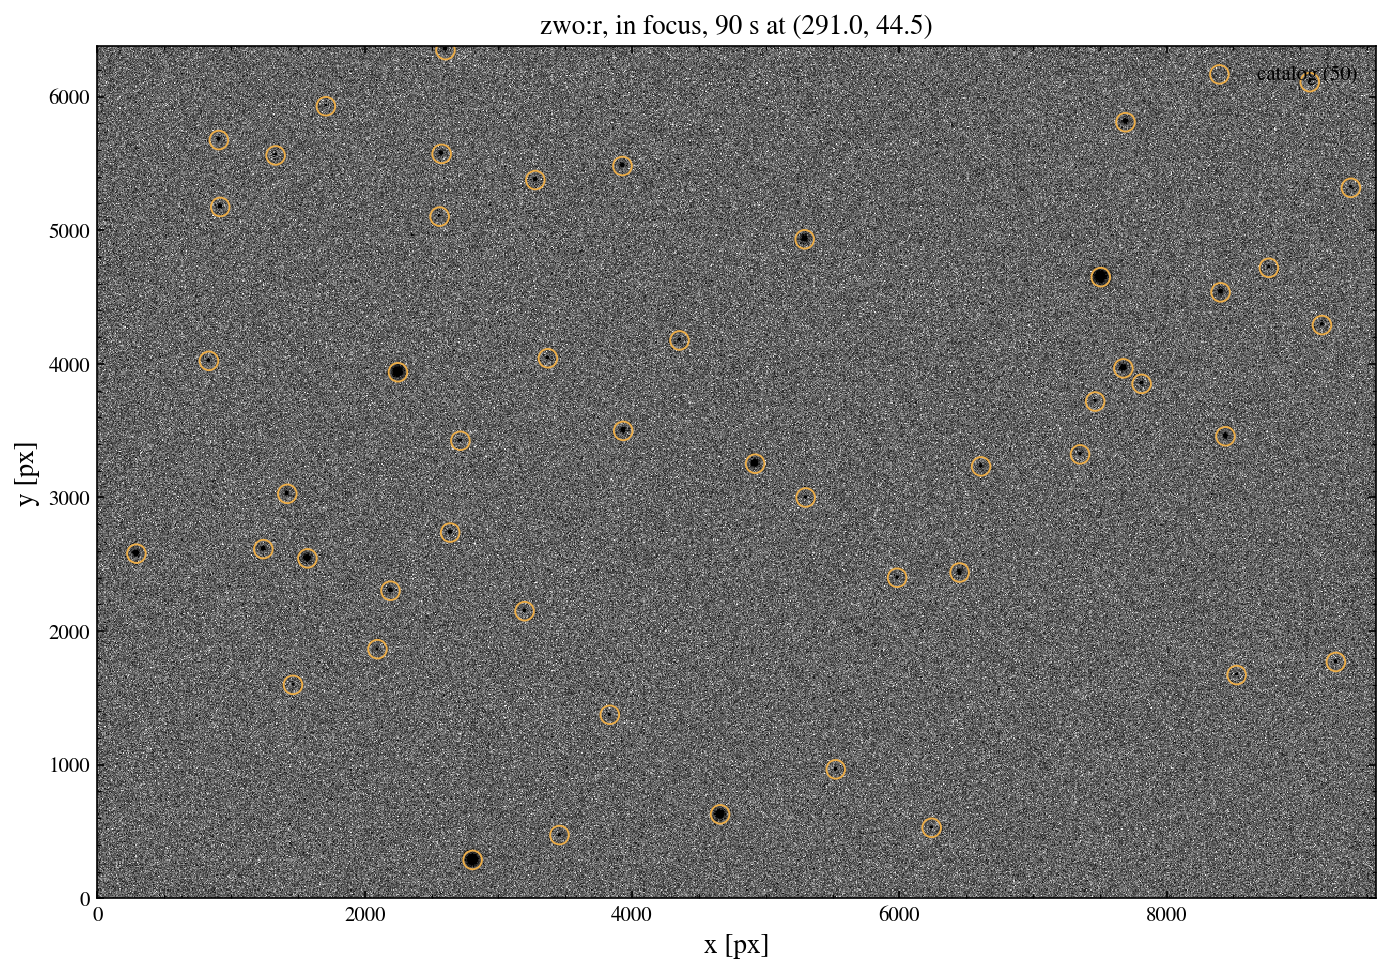

50 of 100 catalog stars land on the array


In [3]:
fig, ax = plt.subplots(figsize=(11, 7.5))
field.plot(ax=ax, catalog=True, percent=99.8)
ax.set_title(f'zwo:r, in focus, {EXPTIME:.0f} s at ({RA0}, {DEC0})')
plt.show()

img = field.image_adu
cat = field.catalog
inside = np.asarray(cat['in_image'], dtype=bool)
print(f'{inside.sum()} of {len(cat)} catalog stars land on the array')

## 3. The three PSF modes on one star

The WCC observes in focus or deliberately defocused by one or two waves, which
spreads bright stars over more pixels. We pick a bright, isolated, unsaturated
star from the catalog and re-simulate a 600 x 600 px subarray centred on its
RA and Dec at each focus level. `plot_cutout()` shows the star on a log stretch
whose floor is the sky level, so the faint Airy rings and the ring-shaped
defocused PSFs are both visible. The defocused PSFs are the Zemax Huygens
models bundled with wcc-etc: the centre is depressed and the light sits in a
ring. Notebook 03 goes deeper into the PSF modes.

In [4]:
from scipy.spatial import cKDTree

xy = np.c_[cat['x'], cat['y']]
tree = cKDTree(xy)
neigh = tree.query(xy, k=2)[0][:, 1]                  # distance to nearest neighbor [px]
sat = np.asarray(cat['saturated'], dtype=bool)
ok = inside & ~sat & (neigh > 180)                    # isolated: > 3 arcsec
star = cat[ok][np.argmin(cat['phot_g_mean_mag'][ok])]
print(f"star: Gaia DR3 {star['source_id']}  G={star['phot_g_mean_mag']:.2f}  "
      f"spt={star['spt']}  rate={star['rate_e_s']:.0f} e-/s")

fields_focus = {}
for foc in (0, 1, 2):
    fields_focus[foc] = simulate_field(
        ra=float(star['ra']), dec=float(star['dec']), sensorfilter='zwo:r',
        focus=foc, exptime=EXPTIME, seed=42, shape=(600, 600),
        cache_dir='gaia_cache',
    )
print('subarray sims done')

star: Gaia DR3 2126245588779207936  G=18.26  spt=G5V  rate=1912 e-/s


/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:35: RuntimeWarning: divide by zero encountered in matmul
  cx = (psf.sum(axis=0) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:35: RuntimeWarning: overflow encountered in matmul
  cx = (psf.sum(axis=0) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:35: RuntimeWarning: invalid value encountered in matmul
  cx = (psf.sum(axis=0) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:36: RuntimeWarning: divide by zero encountered in matmul
  cy = (psf.sum(axis=1) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:36: RuntimeWarning: overflow encountered in matmul
  cy = (psf.sum(axis=1) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:36: RuntimeWarning: invalid value encou

/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:35: RuntimeWarning: divide by zero encountered in matmul
  cx = (psf.sum(axis=0) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:35: RuntimeWarning: overflow encountered in matmul
  cx = (psf.sum(axis=0) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:35: RuntimeWarning: invalid value encountered in matmul
  cx = (psf.sum(axis=0) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:36: RuntimeWarning: divide by zero encountered in matmul
  cy = (psf.sum(axis=1) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:36: RuntimeWarning: overflow encountered in matmul
  cy = (psf.sum(axis=1) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:36: RuntimeWarning: invalid value encou

subarray sims done


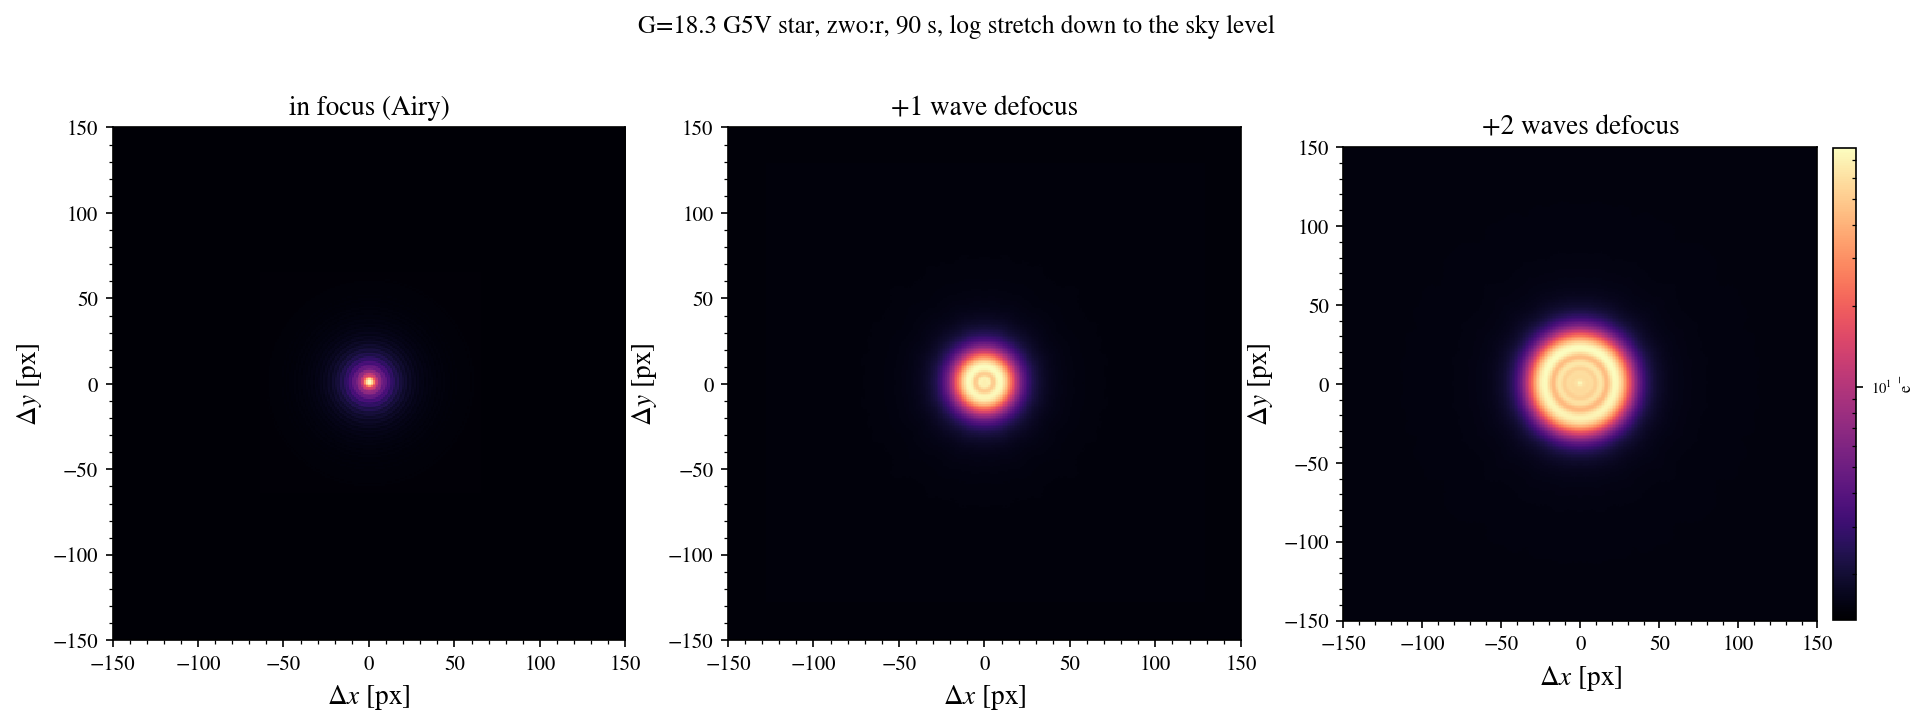

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
titles = ['in focus (Airy)', '+1 wave defocus', '+2 waves defocus']
for ax, foc, title in zip(axes, (0, 1, 2), titles):
    f = fields_focus[foc]
    row = int(np.flatnonzero(f.catalog['source_id'] == star['source_id'])[0])
    f.plot_cutout(ax=ax, star=row, half_width=150, which='clean', cbar=(foc == 2))
    ax.set_title(title)
fig.suptitle(f"G={star['phot_g_mean_mag']:.1f} {star['spt']} star, zwo:r, {EXPTIME:.0f} s, "
             "log stretch down to the sky level", y=1.03)
plt.show()

## 4. Write the FITS file

`field.write()` saves a multi-extension FITS file: the ADU image with the WCS
and every simulation parameter in its header (`SCI`), the saturation mask
(`SATMASK`), the injected catalog (`CAT`) and the noiseless image (`CLEAN`).
Here we write the +1-wave subarray and read it back. Notebook 07 dissects the
file extension by extension.

In [6]:
hdul = fields_focus[1].to_hdulist()   # the +1-wave subarray, as an example
hdul.info()
hdr = hdul['SCI'].header
keys = ['RA_PNT', 'DEC_PNT', 'SENSORF', 'FOCUS', 'EXPTIME', 'NREADS', 'JITTER',
        'PLTSCL', 'GAIN', 'RDNOISE', 'SKYRATE', 'DARK', 'WELLDEP', 'NSRC', 'WCCSIMV', 'WCCETCV']
print()
for k in keys:
    print(f'{k:8s} = {hdr[k]!r:>24}   / {hdr.comments[k]}')

fields_focus[1].write('example_field_1wave.fits')
with fits.open('example_field_1wave.fits') as f_check:
    assert [h.name for h in f_check] == ['SCI', 'SATMASK', 'CAT', 'CLEAN']
print('\nPASS: example_field_1wave.fits written and verified (SCI/SATMASK/CAT/CLEAN)')

Filename: (No file associated with this HDUList)
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SCI           1 PrimaryHDU      65   (600, 600)   float32   
  1  SATMASK       1 ImageHDU         8   (600, 600)   uint8   
  2  CAT           1 BinTableHDU     54   7R x 18C   ['K', 'D', 'D', 'E', 'E', 'E', 'D', 'D', 'D', 'E', 'D', 'D', '3A', 'L', 'D', 'D', 'L', 'L']   
  3  CLEAN         1 ImageHDU         9   (600, 600)   float32   



RA_PNT   =        291.0170189106795   / [deg] pointing RA (ICRS), array center
DEC_PNT  =       44.495842626555834   / [deg] pointing Dec (ICRS), array center
SENSORF  =                  'zwo:r'   / wcc_etc sensorfilter (kind:band)
FOCUS    =                        1   / [waves] defocus (0=in-focus)
EXPTIME  =                     90.0   / [s] total exposure time
NREADS   =                        1   / coadded frames (ETC semantics)
JITTER   =                     10.0   / [mas] jitter Gaussian sigma
PLTSCL   =       16.869089722675366   / [mas/pix] plate scale
GAIN     =        0.261200000004368   / [e-/ADU] sensor gain
RDNOISE  =       3.0442890448219115   / [e-] read noise per frame
SKYRATE  =     0.013643288040258746   / [e-/s/pix] sky background rate
DARK     =    0.0030703367499985944   / [e-/s/pix] dark current
WELLDEP  =       16274.929434794496   / [e-] full well (empty if None)
NSRC     =                        7   / number of injected sources
WCCSIMV  =                  '0.1.

## Summary

- `simulate_field(ra, dec, sensorfilter=..., focus=..., exptime=..., seed=...)`
  returns a `SimulatedField` with `image_adu`, `image_e`, `image_clean`,
  `saturation_mask`, `catalog`, `wcs` and `params`.
- `field.plot(catalog=True)` and `field.plot_cutout(star=...)` draw the standard
  views; notebook 10 shows the rest of the plotting methods.
- `field.write(path)` writes `SCI`, `SATMASK`, `CAT` and `CLEAN`.

The same simulation from the shell:

```bash
wcc-sim --ra 291.0 --dec 44.5 --sensorfilter zwo:r --focus 0 --exptime 90 --seed 42 -o field.fits
```

Next: notebook 02 verifies these images against the ETC prediction, and
notebook 03 explores the PSF modes.